# Noise, Resources and Compiling 


Outline:
1) What happens in real quantum systems?
2) A first Noise Model
3) Resources and Noise
4) Compiling and Optimizing Circuits

Let's start by preparing a Bell State: $$ \phi =\frac{1}{\sqrt{2}} (\ket{00}+\ket{11})$$
and let's see what happens in the ideal scenario

In [1]:
import pennylane as qp
import pennylane.numpy as np

dev = qp.device('default.qubit', wires=2)

@qp.set_shots(shots=100)
@qp.qnode(dev)
def circuit():
    qp.Hadamard(wires=0)
    qp.CNOT(wires=[0,1])
    return qp.counts()


QNode output = {np.str_('00'): np.int64(51), np.str_('11'): np.int64(49)}


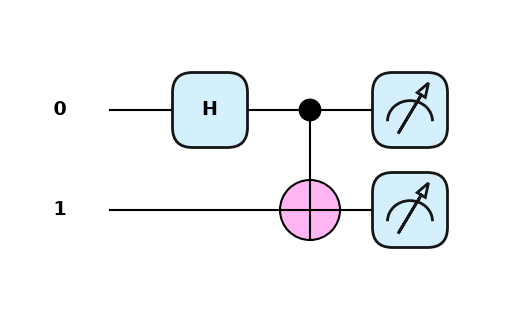

In [2]:
qp.draw_mpl(circuit,style = "pennylane")()
print(f"QNode output = {circuit()}")

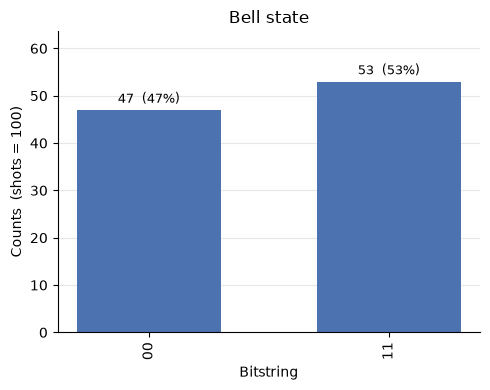

In [6]:
from utils import plot_hist

plot_hist(circuit(),title="Bell state")

But what if we take noise into account? In this case let's consider: `qp.DepolarizingChannel`

First of all, we need a new backend!

In [7]:
dev = qp.device('default.mixed', wires=2)

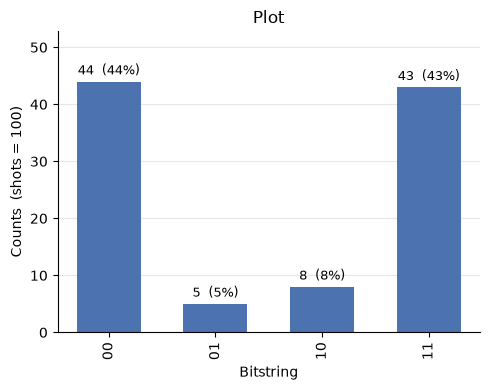

In [9]:
p=.1

@qp.set_shots(shots=100)
@qp.qnode(dev)
def circuit():
    #Bell State Circuit
    qp.Hadamard(wires=0)
    qp.CNOT(wires=[0,1])

    #Noise
    qp.DepolarizingChannel(p,wires=0)
    qp.DepolarizingChannel(p,wires=1)

    return qp.counts()

plot_hist(circuit())

Let's just have as outcome the exp val and change the error probability

In [10]:

@qp.set_shots(shots=100)
@qp.qnode(dev)
def circuit(p):
    #Bell State Circuit
    qp.Hadamard(wires=0)
    qp.CNOT(wires=[0,1])

    #Noise
    qp.DepolarizingChannel(p,wires=0)
    qp.DepolarizingChannel(p,wires=1)

    #Out
    return qp.expval(qp.PauliZ(0) @ qp.PauliZ(1))

ps = [0, 0.001, 0.01, 0.1, 0.2]
for p in ps:
    print(f"QNode output for depolarizing probability {p} is {circuit(p):.4f}")

QNode output for depolarizing probability 0 is 1.0000
QNode output for depolarizing probability 0.001 is 1.0000
QNode output for depolarizing probability 0.01 is 1.0000
QNode output for depolarizing probability 0.1 is 0.7400
QNode output for depolarizing probability 0.2 is 0.5000


# Let's make a proper Noise Model!

It's really annoying to add noise for every gate we use in the circuit's functions defintiions, let's do something better!

In [11]:
noise1 = qp.noise.partial_wires(qp.PhaseFlip, 0.01)

fcond1 = qp.noise.op_eq("Hadamard")

noise2 = qp.noise.partial_wires(qp.BitFlip, 0.02)

fcond2 = qp.noise.op_eq("RX")

noise3 = qp.noise.partial_wires(qp.DepolarizingChannel, 0.2)

fcond3 = qp.noise.op_eq("CNOT")


In [12]:
noise_model = qp.NoiseModel(
    {fcond1: noise1, fcond2: noise2,fcond3: noise3}
)
print(noise_model)

NoiseModel({
    OpEq(Hadamard): PhaseFlip(p=0.01)
    OpEq(RX): BitFlip(p=0.02)
    OpEq(CNOT): DepolarizingChannel(p=0.2)
})


In [13]:
from matplotlib import pyplot as plt

qp.drawer.use_style("pennylane")
dev = qp.device("default.mixed", wires=3)

def circuit(theta, phi):
    # State preparation
    qp.PauliX(0)

    # Evolve state
    qp.Hadamard(0)
    qp.RX(theta, 1)
    qp.RX(phi, 2)
    qp.Hadamard(1)
    qp.CNOT([1, 2])
    qp.CNOT([0, 1])

    # De-evolve state
    qp.CNOT([0, 1])
    qp.CNOT([1, 2])
    qp.RX(-phi, 2)
    qp.RX(-theta, 1)
    qp.Hadamard(0)
    return qp.state()

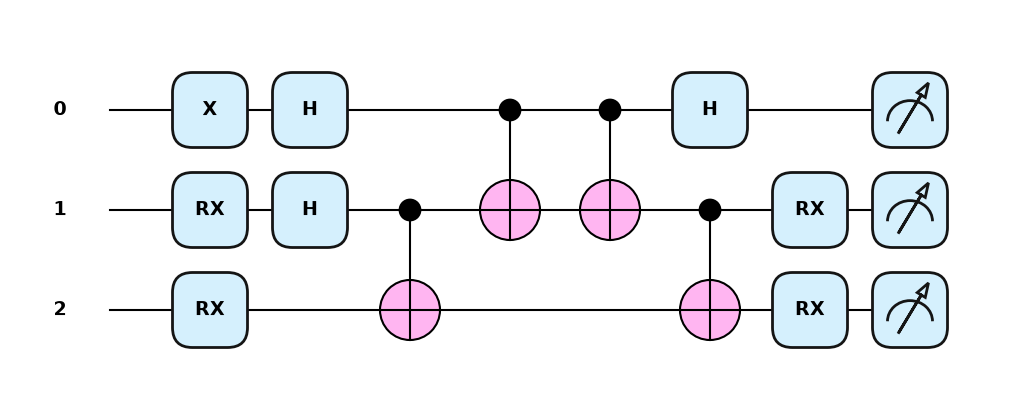

In [14]:
theta, phi = 0.21, 0.43
ideal_circuit = qp.QNode(circuit, dev)
qp.draw_mpl(ideal_circuit)(theta, phi)
plt.show()

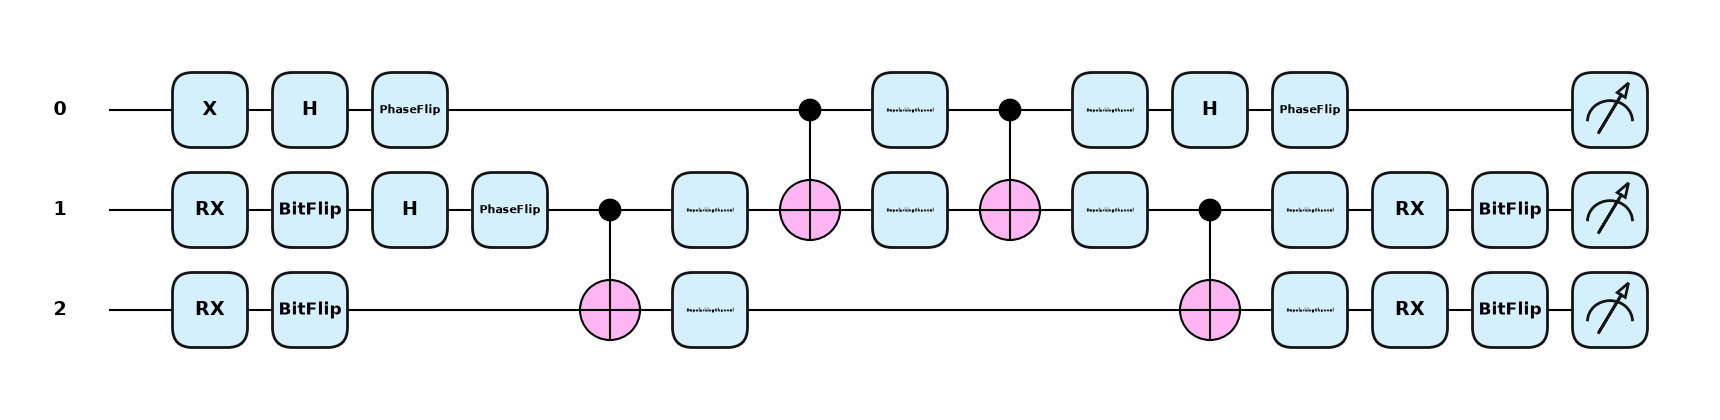

In [15]:
noisy_circuit = qp.add_noise(ideal_circuit, noise_model)
qp.draw_mpl(noisy_circuit)(theta, phi)
plt.show()

### Fidelity

fidelity measures how close two quantum states are (1 = identical, 0 = orthogonal).

For state vectors it is the squared overlap:

$$F(|\psi\rangle, |\phi\rangle) = |\langle \psi | \phi \rangle|^2$$

PennyLane works with the density matrix formalism we haven't seen in the course, but for now we can just use their function `qp.math.fidelity`

In [16]:
noisy_res = np.round(qp.math.fidelity(noisy_circuit(theta, phi), ideal_circuit(theta, phi)), 8)

print(f"Ideal v/s Noisy - Fidelity: { noisy_res}")

Ideal v/s Noisy - Fidelity: 0.26794747


# Excercise:
Write a circuit where you iteratively "append" layers of some arbitrary gates and see what happens to the fidelity of the output state!

In [20]:
def iter(k):
    for _ in range(k):
        qp.Hadamard(wires=0)
        qp.RZ(.3,wires=1)
        qp.RX(.5,wires=2)
    return qp.state()

k_list=[1,3,5,7, 11]
ideal_iter = qp.QNode(iter, dev)
noisy_iter = qp.add_noise(ideal_iter, noise_model)

for k in k_list:
    noisy_res = np.round(qp.math.fidelity(noisy_iter(k), ideal_iter(k)), 4)
    print(f"Number of layers:{k} Fidelity:{noisy_res}")

Number of layers:1 Fidelity:0.9702
Number of layers:3 Fidelity:0.9237
Number of layers:5 Fidelity:0.881
Number of layers:7 Fidelity:0.8417
Number of layers:11 Fidelity:0.7724


# Noise and Resources

Let's go back to the previous circuit example: we can observe the resources required by a circuit

In [21]:
ideal_circuit = qp.QNode(circuit, dev)
qp.specs(ideal_circuit)(theta, phi)

Device: default.mixed
Device wires: 3
Shots: Shots(total=None)
Level: gradient

Wire allocations: 3
Total gates: 12
Gate counts:
- PauliX: 1
- Hadamard: 3
- RX: 4
- CNOT: 4
Measurements:
- state(all wires): 1
Depth: 7


Let's use some compiling strategies (called transforms in Pennylane) allowing to simplify/optimize circuits. Here we'll use two simple ones: merge rotations and cancel inverses. Other transforms can be found here https://docs.pennylane.ai/en/stable/introduction/compiling_circuits.html

In [22]:
@qp.transforms.merge_rotations
@qp.transforms.cancel_inverses(recursive=True)
@qp.transforms.cancel_inverses(recursive=True)
def opt_circuit(theta, phi):
    # State preparation
    qp.PauliX(0)

    # Evolve state
    qp.Hadamard(0)
    qp.RX(theta, 1)
    qp.RX(phi, 2)
    qp.Hadamard(1)

    qp.CNOT([1, 2])
    qp.CNOT([0, 1])

    # De-evolve state
    qp.CNOT([0, 1])
    qp.CNOT([1, 2])
    qp.RX(-phi, 2)
    qp.RX(-theta, 1)
    qp.Hadamard(0)
    return qp.state()

opt_qnode = qp.QNode(opt_circuit, dev)
qp.specs(opt_qnode)(theta, phi)


Device: default.mixed
Device wires: 3
Shots: Shots(total=None)
Level: gradient

Wire allocations: 2
Total gates: 4
Gate counts:
- PauliX: 1
- RX: 2
- Hadamard: 1
Measurements:
- state(all wires): 1
Depth: 3


(<Figure size 600x300 with 1 Axes>, <Axes: >)

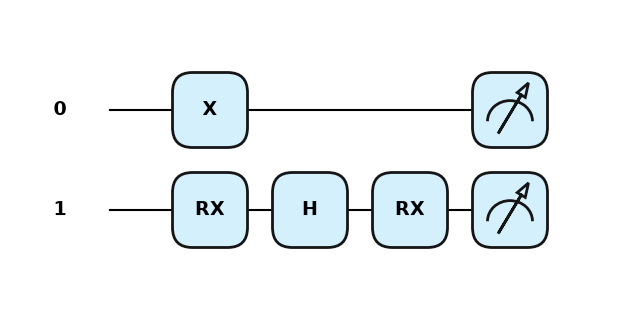

In [23]:
qp.draw_mpl(opt_circuit)(theta, phi)

In [24]:
noisy_circuit=qp.add_noise(ideal_circuit,noise_model)
noisy_opt_circuit = qp.add_noise(opt_qnode, noise_model)

ideal_res = np.round(qp.math.fidelity(ideal_circuit(theta, phi), ideal_circuit(theta, phi)), 8)
noisy_res = np.round(qp.math.fidelity(noisy_circuit(theta, phi), ideal_circuit(theta, phi)), 8)

ideal_opt_res = np.round(qp.math.fidelity(opt_qnode(theta, phi), ideal_circuit(theta, phi)), 8)
noisy_opt_res = np.round(qp.math.fidelity(noisy_opt_circuit(theta, phi), ideal_circuit(theta, phi)), 8)

print(f"Ideal: {ideal_res:.3f}, Ideal Opt: {ideal_opt_res:.3f}")
print(f"Noisy: {noisy_res:.3f}, Noisy Opt: {noisy_opt_res:.3f}")

Ideal: 1.000, Ideal Opt: 1.000
Noisy: 0.268, Noisy Opt: 0.970


# A concrete compiling example:

Here we take into account a more serious example with compiling and gate decomposition into Native Gates of a quantum hardware

In [25]:

num_qubits=4
dev=qp.device("default.mixed", wires=num_qubits)

# Let's take our Grover implementation 

def grover_circuit(k=1):
    combos = [[0,1,0]]
    n_bits=len(combos[0])
    query_register = list(range(n_bits))
    aux = [n_bits]
    all_wires = query_register + aux

    def oracle(combos):
        for combo in combos:
            qp.MultiControlledX(wires=all_wires,control_values=combo)

    def diffusion():
        for wire in query_register:
            qp.Hadamard(wires=wire)
        qp.MultiControlledX(wires=all_wires, control_values=[0 for _ in query_register])
        for wire in query_register:
            qp.Hadamard(wires=wire)

    qp.X(wires=aux)
    for wire in all_wires:
        qp.Hadamard(wires=wire)
    for _ in range(k):
        oracle(combos)
        diffusion()
    return qp.state()

(<Figure size 900x500 with 1 Axes>, <Axes: >)

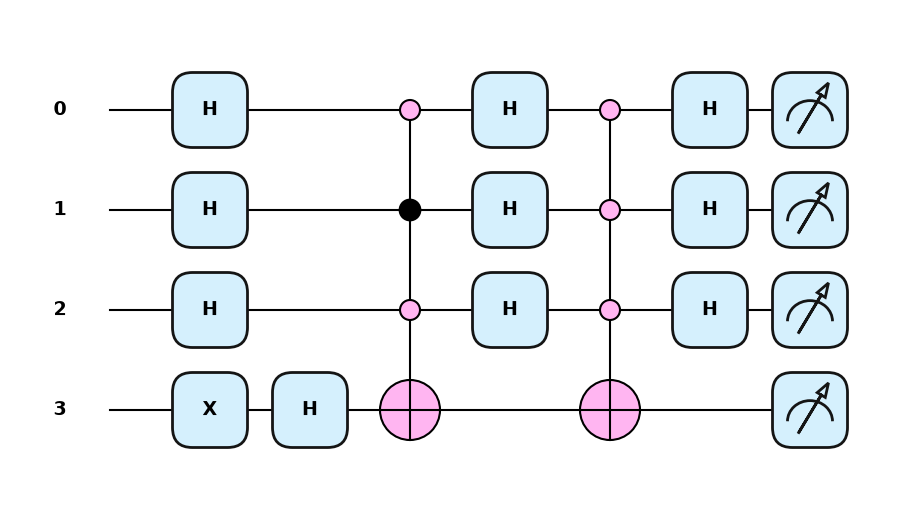

In [26]:
qp.draw_mpl(grover_circuit)()

What about Hardware?

In [27]:
import networkx as nx

# Native Gates Set
gate_set={qp.RX, qp.RZ,qp.RY, qp.CNOT}

# Coupling Map
topology = nx.path_graph(num_qubits)   
coupling_map = list(topology.edges)

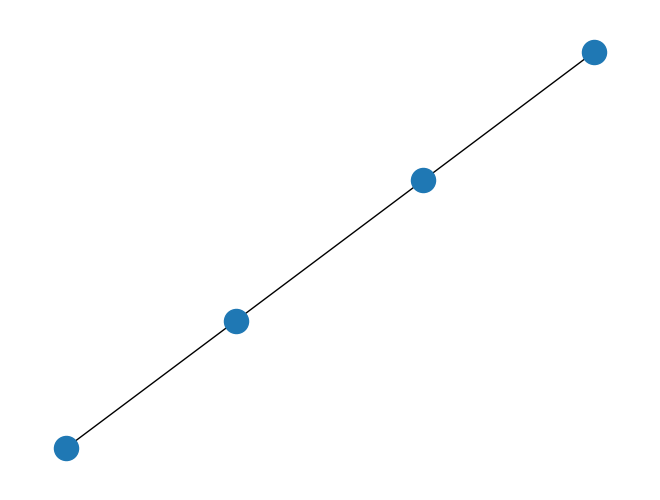

In [28]:
nx.draw(topology)

In [29]:
#Compile without hardware constraints

pipeline_1 = qp.CompilePipeline(
    qp.transforms.commute_controlled,
    qp.transforms.cancel_inverses(recursive=True),
    qp.transforms.merge_rotations,
    qp.transforms.single_qubit_fusion
)

#Compile with native gates constraints

pipeline_2 = qp.CompilePipeline(
    qp.transforms.decompose(gate_set=gate_set),
    qp.transforms.commute_controlled,
    qp.transforms.cancel_inverses(recursive=True),
    qp.transforms.merge_rotations,
    qp.transforms.single_qubit_fusion,
    qp.transforms.decompose(gate_set=gate_set)
)

#Compile with native gates and topology constraints

pipeline_3 = qp.CompilePipeline(
    qp.transforms.decompose(gate_set=gate_set),
    qp.transforms.transpile(coupling_map=coupling_map),
    qp.transforms.commute_controlled,
    qp.transforms.cancel_inverses(recursive=True),
    qp.transforms.merge_rotations,
    qp.transforms.single_qubit_fusion,
    qp.transforms.decompose(gate_set=gate_set)
)

In [30]:
input_qnode=qp.QNode(grover_circuit, dev)

compiled_qnode1 = pipeline_1(input_qnode)
compiled_qnode2 = pipeline_2(input_qnode)
compiled_qnode3 = pipeline_3(input_qnode)

compiling_nodes={"High level": compiled_qnode1,"Native Gates" :compiled_qnode2,"Native Gates+CM":compiled_qnode3}


In [31]:
print("")
for name,el in compiling_nodes.items():
    res=qp.specs(el, level="user")()
    print(f"\n Approach: {name}")
    print(f"Total gates: {res.resources.num_gates}, Depth: {res.resources.depth}, # Gates: {res.resources.gate_counts}")
    



 Approach: High level
Total gates: 13, Depth: 6, # Gates: {'Rot': 7, 'MultiControlledX': 2, 'Hadamard': 3, 'GlobalPhase': 1}

 Approach: Native Gates
Total gates: 226, Depth: 155, # Gates: {'RZ': 119, 'RY': 59, 'CNOT': 48}

 Approach: Native Gates+CM
Total gates: 292, Depth: 205, # Gates: {'RZ': 135, 'RY': 67, 'CNOT': 90}


(<Figure size 16400x500 with 1 Axes>, <Axes: >)



In [32]:
qp.draw_mpl(compiled_qnode2)()

# FTQC Compiling

(<Figure size 1000x500 with 1 Axes>, <Axes: >)

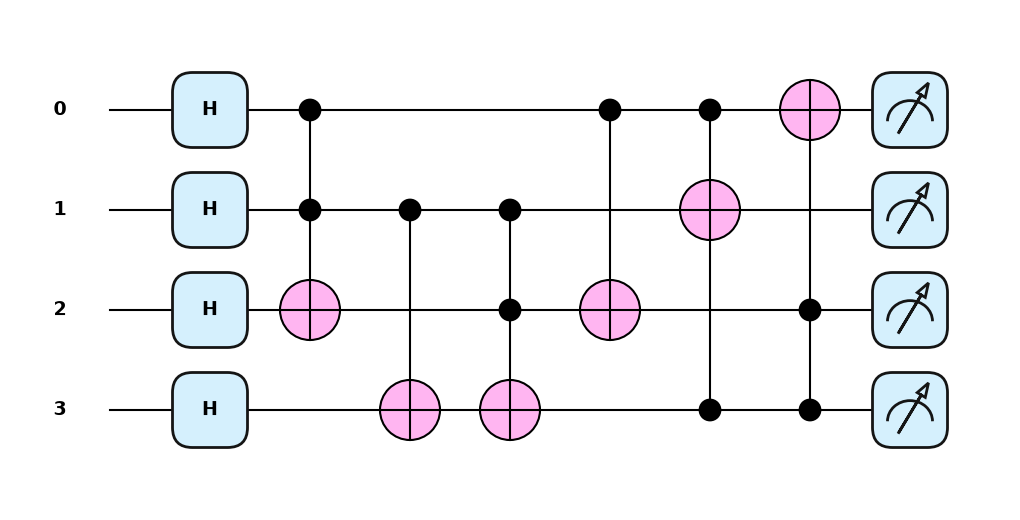

In [33]:
dev = qp.device("default.qubit", wires=4)

@qp.qnode(dev)
def toffoli_circuit():
    for w in range(4):
        qp.Hadamard(w)
    qp.Toffoli([0, 1, 2])
    qp.CNOT([1, 3])
    qp.Toffoli([1, 2, 3])
    qp.CNOT([0, 2])
    qp.Toffoli([0, 3, 1])
    qp.Toffoli([2, 3, 0])
    return qp.state()

qp.draw_mpl(toffoli_circuit)()

In [34]:

# NISQ target
nisq_gates = {qp.RX, qp.RY, qp.RZ, qp.CNOT}
nisq = qp.CompilePipeline(
    qp.transforms.decompose(gate_set=nisq_gates),
    qp.transforms.commute_controlled,
    qp.transforms.cancel_inverses(recursive=True),
    qp.transforms.merge_rotations,
    qp.transforms.single_qubit_fusion,
    qp.transforms.decompose(gate_set=nisq_gates),
)


nisq_q = nisq(toffoli_circuit)
qp.specs(nisq_q)()

Device: default.qubit
Device wires: 4
Shots: Shots(total=None)
Level: gradient

Wire allocations: 4
Total gates: 120
Gate counts:
- RZ: 63
- RY: 31
- CNOT: 26
Measurements:
- state(all wires): 1
Depth: 86


In [35]:

# FTQC target
clifford_t = {"Hadamard", "S", "Adjoint(S)", "T", "Adjoint(T)", "CNOT", "PauliX", "PauliZ", "GlobalPhase"}
ft_base = qp.transforms.decompose(toffoli_circuit, gate_set=clifford_t)
ft_opt = qp.transforms.zx.optimize_t_count(ft_base)

def report(name, qnode):
    res = qp.specs(qnode, level="user")().resources
    g = res.gate_counts
    n_t = g.get("T", 0) + g.get("Adjoint(T)", 0)
    print(f"{name:18s} CNOT={g.get('CNOT', 0):3d}  T={n_t:3d}  depth={res.depth}")

routes = [
    ("Clifford+T", ft_base),
    ("Clifford+T -> ZX", ft_opt),
]
ref = toffoli_circuit()
for name, q in routes:
    report(name, q)

Clifford+T         CNOT= 26  T= 28  depth=46
Clifford+T -> ZX   CNOT= 38  T= 22  depth=58


If we have a NISQ device with the `clifford_t` gate set, which approach above would work better?